<a href="https://colab.research.google.com/github/ainankhan-pixel/231A052_NLP_Lab/blob/main/NLPL_exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from datasets import load_dataset

# Load complete IMDB dataset
dataset = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
df=pd.concat(
  [dataset["train"].to_pandas(),
   dataset["test"].to_pandas()],
   ignore_index=True)

In [ ]:
df=df.rename(columns={"label":"labels"})

In [ ]:
print("\nMissing values:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

df["char_count"]=df["text"].astype(str).apply(len)
df["word_count"]=df["text"].astype(str).apply(lambda x: len(x.lower().split()))
df["unique_word_count"]=df["text"].astype(str).apply(lambda x: len(set(x.split())))
df["average_word_length"]=df["text"].astype(str).apply(lambda x: sum(len(word) for word in x.split()) / max(len(x.split()), 1))
print("\nText Statistics")

print(df[["char_count","word_count","unique_word_count","average_word_length"]].describe())


Missing values:
text     0
label    0
dtype: int64

Number of duplicate rows:
418

Text Statistics
         char_count    word_count  unique_word_count  average_word_length
count  50000.000000  50000.000000        50000.00000         50000.000000
mean    1309.431020    231.156940          152.14090             4.640676
std      989.728014    171.343997           91.76515             0.340731
min       32.000000      4.000000            4.00000             1.239865
25%      699.000000    126.000000           94.00000             4.417904
50%      970.000000    173.000000          123.00000             4.627006
75%     1590.250000    280.000000          185.00000             4.847458
max    13704.000000   2470.000000         1118.00000            12.290909


In [ ]:
def clean_text(text):
  text = text.lower()
  text = re.sub(r"<.*?>"," ",text)
  text =re.sub(r"[^a-z\s]"," ",text)
  text =re.sub(r"\s+"," ",text).strip()
  return text

  df["clean_text"]=df["text"].astype(str).apply(clean_text)

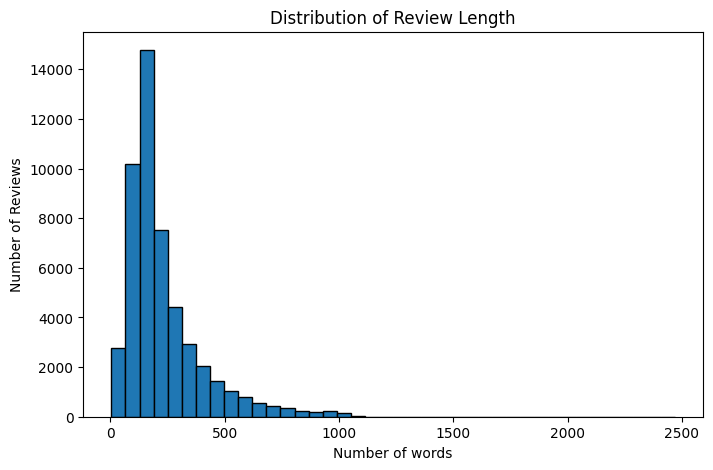

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["word_count"],bins=40,edgecolor="black")
plt.xlabel("Number of words")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Review Length")
plt.show()

In [ ]:
import re
from collections import Counter

# Correctly clean the text and create the column
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].astype(str).apply(clean_text)

# Calculate word metrics and frequencies
all_words = " ".join(df["clean_text"]).split()
print("total numbers of words:", len(all_words))
print("vocabulary size:", len(set(all_words)))

words_freq = Counter(all_words)
top_words = words_freq.most_common(20)
print("\nTop 20 words:", top_words)

total numbers of words: 11709196
vocabulary size: 99420

Top 20 words: [('the', 668009), ('and', 324439), ('a', 323060), ('of', 289415), ('to', 268123), ('is', 211092), ('it', 190862), ('in', 186787), ('i', 175627), ('this', 151001), ('that', 143881), ('s', 129791), ('was', 95606), ('as', 91764), ('movie', 87972), ('for', 87471), ('with', 87368), ('but', 83553), ('film', 79708), ('you', 69131)]


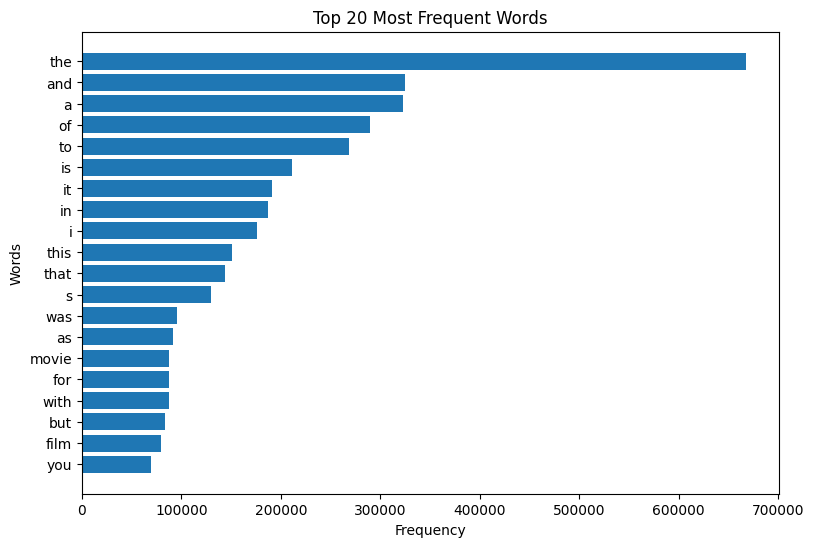

In [ ]:
words = [word for word, count in top_words]
counts = [count for word, count in top_words]
plt.figure(figsize= (9, 6))
plt.barh (words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words")
plt.show()

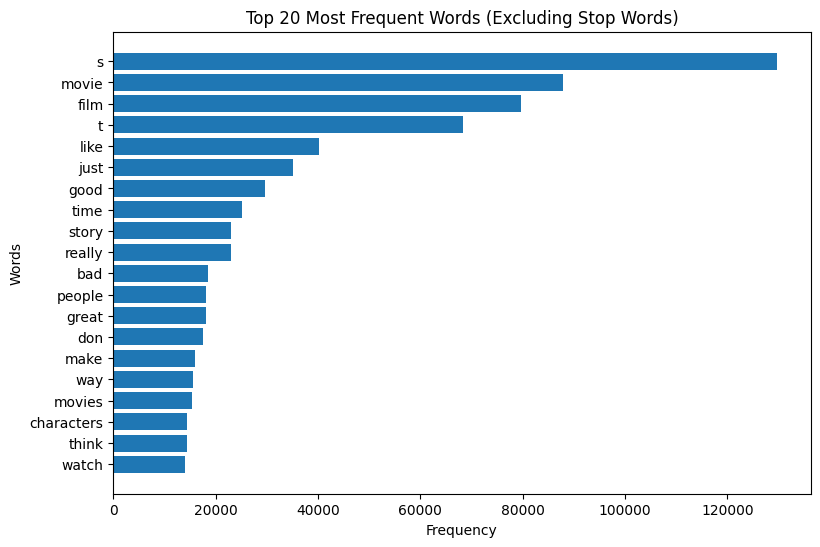

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter
import matplotlib.pyplot as plt

# Initialize and fit CountVectorizer to get English stop words
vectorizer = CountVectorizer(stop_words="english")
vectorizer.fit(df["clean_text"])
stop_words = vectorizer.get_stop_words()

# Filter words
filtered_words = [word for word in all_words if word not in stop_words]
filtered_freq = Counter(filtered_words)
top_filtered = filtered_freq.most_common(20)

# Prepare and display the bar chart
words = [word for word, count in top_filtered]
counts = [count for word, count in top_filtered]

plt.figure(figsize=(9, 6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words (Excluding Stop Words)")
plt.show()

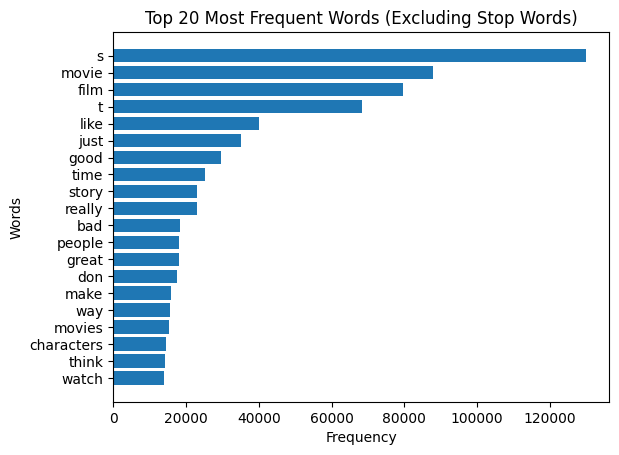

In [ ]:
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words (Excluding Stop Words)")
plt.show()

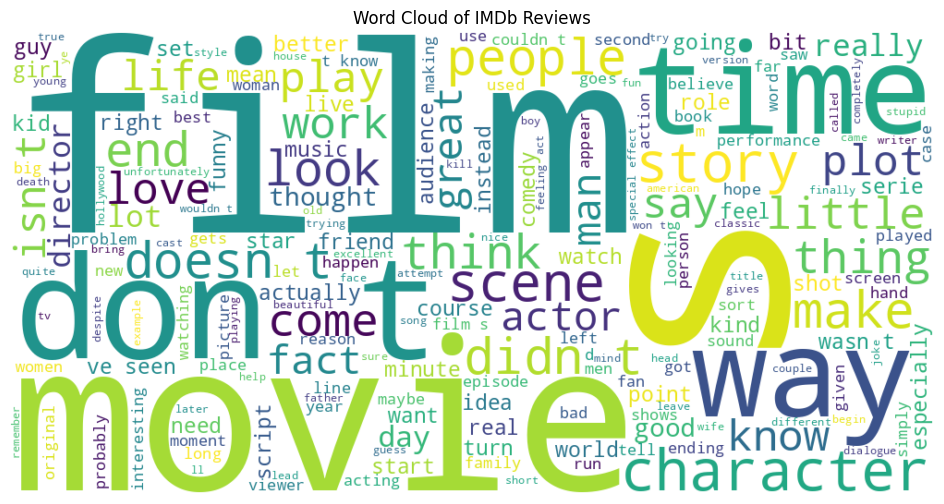

In [ ]:
#9. WORD CLOUD
from wordcloud import WordCloud
import matplotlib.pyplot as plt

clean_text_combined = " ".join(filtered_words)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(clean_text_combined)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of IMDb Reviews")
plt.show()

In [ ]:
#10. BIGRAM ANALYSIS
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=20
)

# Fit and transform the clean review text
bigram_matrix = bigram_vectorizer.fit_transform(df["clean_text"])
bigram_counts = bigram_matrix.sum(axis=0).A1
bigram_names = bigram_vectorizer.get_feature_names_out()

bigram_df = pd.DataFrame({
    "Bigram": bigram_names,
    "Frequency": bigram_counts
})

print(bigram_df.sort_values(by="Frequency", ascending=False))

             Bigram  Frequency
15          ve seen       4168
14  special effects       2250
0          don know       2202
6        low budget       1824
5        looks like       1679
18         year old       1601
8        movie just       1543
16       waste time       1526
2        good movie       1520
13           sci fi       1393
17      watch movie       1379
10         new york       1317
4         look like       1313
1         don think       1305
19        years ago       1256
12        real life       1240
3       high school       1164
7    main character       1140
11      pretty good       1120
9        movie like       1095


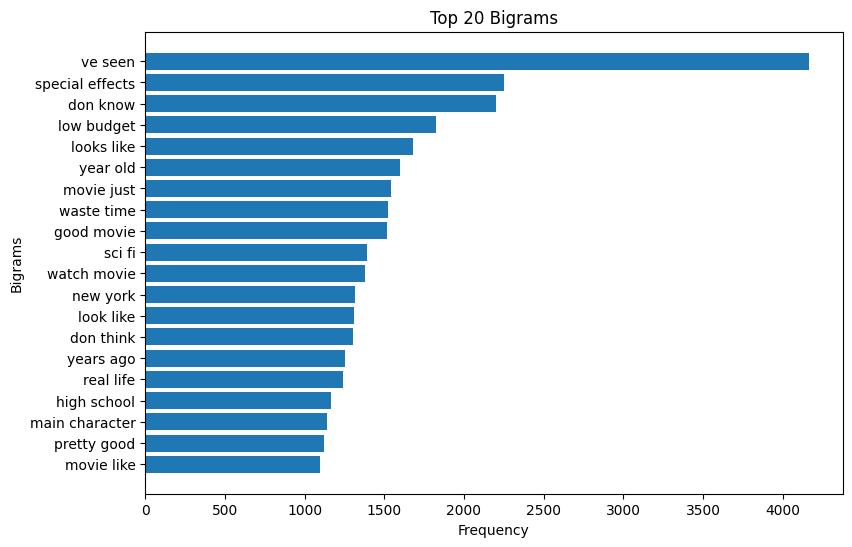

In [ ]:
# PLOT TOP BIGRAMS
import matplotlib.pyplot as plt

# Sort bigram_df to plot the most frequent bigrams in ascending order for barh
sorted_bigrams = bigram_df.sort_values(by="Frequency", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(
    sorted_bigrams["Bigram"],
    sorted_bigrams["Frequency"]
)
plt.xlabel("Frequency")
plt.ylabel("Bigrams")
plt.title("Top 20 Bigrams")
plt.show()